<a href="https://colab.research.google.com/github/aashrencs24/BIS_LAB_1BF24CS006/blob/main/Week_3_ant_colony_telenetwork.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

--- Starting AntNet Simulation (300 steps) ---

[Step 100/300] Routing Probabilities (Node 0 -> Dest 3):
  ➜ Next Hop 1:  100.0% (1.000)
  ➜ Next Hop 2:    0.0% (0.000)
  ➜ Next Hop 7:    0.0% (0.000)

[Step 200/300] Routing Probabilities (Node 0 -> Dest 3):
  ➜ Next Hop 1:  100.0% (1.000)
  ➜ Next Hop 2:    0.0% (0.000)
  ➜ Next Hop 7:    0.0% (0.000)

[Step 300/300] Routing Probabilities (Node 0 -> Dest 3):
  ➜ Next Hop 1:  100.0% (1.000)
  ➜ Next Hop 2:    0.0% (0.000)
  ➜ Next Hop 7:    0.0% (0.000)


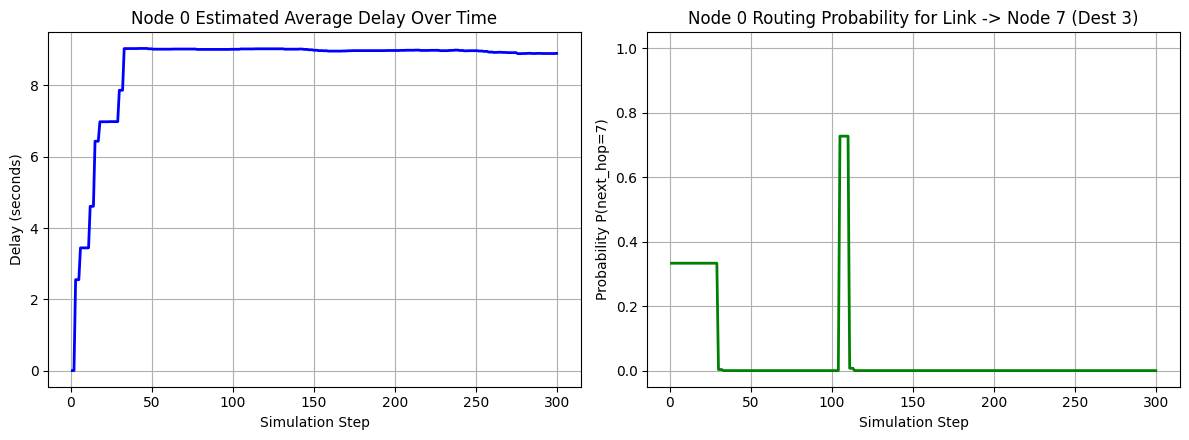

In [3]:
import numpy as np
import random
from collections import defaultdict, deque
import matplotlib.pyplot as plt


def plot_antnet_metrics(step_history, delay_history, prob_history):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))

    # 1. Plot Average Delay Convergence
    ax1.plot(step_history, delay_history, color='blue', linewidth=2)
    ax1.set_title("Node 0 Estimated Average Delay Over Time")
    ax1.set_xlabel("Simulation Step")
    ax1.set_ylabel("Delay (seconds)")
    ax1.grid(True)

    # 2. Plot Routing Table Probability Convergence
    ax2.plot(step_history, prob_history, color='green', linewidth=2)
    ax2.set_title("Node 0 Routing Probability for Link -> Node 7 (Dest 3)")
    ax2.set_xlabel("Simulation Step")
    ax2.set_ylabel("Probability P(next_hop=7)")
    ax2.set_ylim(-0.05, 1.05)
    ax2.grid(True)

    plt.tight_layout()
    plt.show()


# =====================================================================
# 1. NETWORK NODE CLASS (Routing Table + Local Traffic Model M)
# =====================================================================
class NetworkNode:
    def __init__(self, node_id, neighbors, total_nodes, eta=0.005, c1=0.7, c2=0.3):
        self.id = node_id
        self.neighbors = neighbors
        self.total_nodes = total_nodes
        self.eta = eta  # Learning rate for statistical model M
        self.c1 = c1
        self.c2 = c2

        # Routing Table T[destination][neighbor] -> probability
        self.T = {}
        for dest in range(total_nodes):
            self.T[dest] = {}
            num_neigh = len(neighbors)
            for neigh in neighbors:
                self.T[dest][neigh] = 1.0 / num_neigh if num_neigh > 0 else 0.0

        # Local Model M[destination] -> {mean (mu), variance (sigma^2), best_win (W_best)}
        self.M = {}
        for dest in range(total_nodes):
            self.M[dest] = {
                'mu': 0.0,
                'sigma2': 0.0,
                'window': deque(maxlen=int(5 * (0.3 / eta))),  # Observation window W
                'W_best': float('inf')
            }

        # Simulated outgoing link queues (packets waiting to be sent)
        self.queues = {neigh: deque() for neigh in neighbors}

    def select_next_hop(self, destination, is_ant=False, alpha=0.3):
        if destination not in self.T or not self.neighbors:
            return random.choice(self.neighbors) if self.neighbors else None

        probs = {}

        if is_ant:
            # Heuristic factor based on current link queue lengths
            total_queue_len = sum(len(self.queues[n]) for n in self.neighbors)
            l_n = {}
            for n in self.neighbors:
                q_len = len(self.queues[n])
                l_n[n] = (1.0 - (q_len / total_queue_len)) if total_queue_len > 0 else 1.0

            l_sum = sum(l_n.values())
            l_n = {n: l_n[n] / l_sum if l_sum > 0 else 1.0 / len(self.neighbors) for n in self.neighbors}

            # Combine routing probability P_nd with heuristic correction l_n
            for n in self.neighbors:
                p_raw = (self.T[destination][n] + alpha * l_n[n]) / (1.0 + alpha * (len(self.neighbors) - 1))
                probs[n] = p_raw
        else:
            # Data packets use direct routing probabilities (with power mapping)
            for n in self.neighbors:
                probs[n] = self.T[destination][n] ** 1.2

        # Normalize choices
        total_p = sum(probs.values())
        neighbors_list = list(probs.keys())
        p_dist = [probs[n] / total_p for n in neighbors_list] if total_p > 0 else [1.0 / len(neighbors_list)] * len(neighbors_list)

        return np.random.choice(neighbors_list, p=p_dist)

    def update_model_and_routing_table(self, destination, next_hop, trip_time):
        model = self.M[destination]

        # 1. Update Statistical Traffic Model M
        if model['mu'] == 0.0:
            model['mu'] = trip_time
            model['sigma2'] = (trip_time / 2.0) ** 2
        else:
            diff = trip_time - model['mu']
            model['mu'] += self.eta * diff
            model['sigma2'] += self.eta * ((diff ** 2) - model['sigma2'])

        model['window'].append(trip_time)
        model['W_best'] = min(model['window'])

        # 2. Compute Reinforcement Signal r
        w_best = model['W_best']
        mu = model['mu']
        sigma = np.sqrt(max(model['sigma2'], 1e-6))

        I_inf = w_best
        I_sup = mu + 1.70 * (sigma / np.sqrt(max(len(model['window']), 1)))

        term1 = w_best / max(trip_time, 1e-6)
        denom = (I_sup - I_inf) + (trip_time - I_inf)
        term2 = (I_sup - I_inf) / denom if denom > 0 else 0.5

        r_raw = self.c1 * term1 + self.c2 * term2
        r_raw = np.clip(r_raw, 0.0, 1.0)

        # Squash function
        def squash(x, num_neigh):
            a = 0.5
            return 1.0 / (1.0 + np.exp(-a * x * num_neigh))

        r = squash(r_raw, len(self.neighbors)) / squash(1.0, len(self.neighbors))
        r = np.clip(r, 0.01, 0.99)

        # 3. Update Probabilistic Routing Table T
        for n in self.neighbors:
            if n == next_hop:
                self.T[destination][n] += r * (1.0 - self.T[destination][n])
            else:
                self.T[destination][n] -= r * self.T[destination][n]


# =====================================================================
# 2. ANT AGENTS (Forward & Backward Ants)
# =====================================================================
class ForwardAnt:
    def __init__(self, source, destination, start_time):
        self.source = source
        self.destination = destination
        self.current_node = source
        self.start_time = start_time
        self.memory_stack = [(source, 0.0)]  # [(node_id, elapsed_time)]

    def visit_node(self, node_id, elapsed_time):
        visited_nodes = [item[0] for item in self.memory_stack]
        if node_id in visited_nodes:
            idx = visited_nodes.index(node_id)
            self.memory_stack = self.memory_stack[:idx + 1]
        else:
            self.memory_stack.append((node_id, elapsed_time))
        self.current_node = node_id


class BackwardAnt:
    def __init__(self, forward_ant):
        self.source = forward_ant.destination
        self.destination = forward_ant.source
        self.memory_stack = forward_ant.memory_stack[:]
        self.total_trip_time = forward_ant.memory_stack[-1][1]


# =====================================================================
# 3. NETWORK ENVIRONMENT SIMULATOR
# =====================================================================
class AntNetSimulator:
    def __init__(self, topology_graph, link_delays):
        self.graph = topology_graph
        self.link_delays = link_delays
        self.num_nodes = len(topology_graph)
        self.nodes = {
            i: NetworkNode(i, topology_graph[i], self.num_nodes)
            for i in range(self.num_nodes)
        }

    def run_simulation(self, steps=300):
        print(f"--- Starting AntNet Simulation ({steps} steps) ---")

        step_history = []
        delay_history = []
        prob_history_node7 = []

        for step in range(1, steps + 1):
            current_time = step * 0.1  # 0.1 second per step

            # Step A: Launch Forward Ants periodically
            if step % 3 == 0:  # Every 0.3s
                for src in range(self.num_nodes):
                    dest = random.choice([d for d in range(self.num_nodes) if d != src])
                    ant = ForwardAnt(src, dest, current_time)
                    self._process_forward_ant(ant, current_time)

            # Record step metrics
            step_history.append(step)
            prob_n7 = float(self.nodes[0].T[3].get(7, 0.0))
            prob_history_node7.append(prob_n7)

            avg_delay = np.mean([model['mu'] for model in self.nodes[0].M.values()])
            delay_history.append(avg_delay)

            # Clean terminal output every 100 steps
            if step % 100 == 0:
                print(f"\n[Step {step}/{steps}] Routing Probabilities (Node 0 -> Dest 3):")
                probs = self.nodes[0].T[3]
                for neighbor, p in probs.items():
                    print(f"  ➜ Next Hop {neighbor}: {float(p) * 100:6.1f}% ({float(p):.3f})")

        # Plot graphs at the end of the simulation
        plot_antnet_metrics(step_history, delay_history, prob_history_node7)

    def _process_forward_ant(self, ant, current_time):
        max_hops = self.num_nodes * 2
        hops = 0

        while ant.current_node != ant.destination and hops < max_hops:
            curr_node_obj = self.nodes[ant.current_node]
            next_node = curr_node_obj.select_next_hop(ant.destination, is_ant=True)

            if next_node is None:
                break

            delay = self.link_delays.get((ant.current_node, next_node), 1.0)
            queue_delay = len(curr_node_obj.queues[next_node]) * 0.1
            total_step_delay = delay + queue_delay

            elapsed = ant.memory_stack[-1][1] + total_step_delay
            ant.visit_node(next_node, elapsed)
            hops += 1

        if ant.current_node == ant.destination:
            back_ant = BackwardAnt(ant)
            self._process_backward_ant(back_ant)

    def _process_backward_ant(self, back_ant):
        stack = back_ant.memory_stack
        for i in range(len(stack) - 1, 0, -1):
            curr_node, curr_time = stack[i]
            prev_node, prev_time = stack[i - 1]

            subpath_trip_time = back_ant.total_trip_time - prev_time
            destination_node = stack[-1][0]

            self.nodes[prev_node].update_model_and_routing_table(
                destination=destination_node,
                next_hop=curr_node,
                trip_time=subpath_trip_time
            )


# =====================================================================
# 4. EXECUTION EXAMPLE
# =====================================================================
if __name__ == "__main__":
    topology = {
        0: [1, 2, 7],
        1: [0, 2, 3],
        2: [0, 1, 4],
        3: [1, 5],
        4: [2, 5],
        5: [3, 4, 6],
        6: [5, 7],
        7: [0, 6]
    }

    delays = {}
    for u in topology:
        for v in topology[u]:
            delays[(u, v)] = random.uniform(1.0, 5.0)

    sim = AntNetSimulator(topology, delays)
    sim.run_simulation(steps=300)